
# E6 — Capacity-Constrained Intervention Policy under LOSO Population Shift

## Scientific objective

E4 showed that a source-derived decision threshold does not transfer uniformly across unseen student populations.  
E5 showed that class-conditional conformal prediction can reduce hidden high-stress undercoverage, but uncertainty sets also create abstention burden.

E6 translates those findings into an operational question:

> **When an institution can intervene for only a limited fraction of students, which policy captures the most high-stress cases while controlling intervention burden?**

## LOSO design

For each held-out `Student_Type` and each repeat:

1. the other two populations are source data;
2. source data are split 80/20 into:
   - proper training,
   - source calibration;
3. group-blind Logistic Regression is fitted on proper training only;
4. the calibration split is used to learn:
   - a Recall≥0.80 threshold,
   - Mondrian conformal thresholds at nominal 90% coverage;
5. the held-out population remains label-unseen during policy construction;
6. labels are used only for final evaluation.

## Capacity levels

\[
K \in \{10\%, 15\%, 20\%, 25\%\}
\]

## Capacity-constrained policies

### 1. RiskTopK
Select the highest predicted risks until capacity \(K\) is full.

### 2. ConformalHighOnly
Only singleton `{High}` cases are eligible.  
If fewer singleton-high cases exist than capacity, capacity is intentionally left unused.

### 3. ConformalTriageTopK
Priority:
1. singleton `{High}`;
2. ambiguous `{Low, High}`, ranked by predicted risk;
3. singleton `{Low}`, only if capacity still remains.

This represents uncertainty-aware triage rather than pure score ranking.

## Non-capacity benchmark

### SourceRecall80
Apply the source-calibration threshold satisfying:

\[
Recall \ge 0.80
\]

This policy is not forced to obey \(K\). It estimates how much intervention capacity would actually be required to pursue a sensitivity target learned from source populations.

## Primary operational metrics

- Precision@K
- Recall@K
- Lift@K
- high-stress cases captured
- number needed to review (NNR)
- intervention rate
- capacity utilization
- false-positive interventions
- missed high-stress cases
- uncertainty share among selected cases
- worst-group Recall@K across held-out populations


In [1]:

from pathlib import Path
import platform, json, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve

SEED = 42
TARGET = "Stress_Level"
GROUP = "Student_Type"

N_REPEATS = 5
SOURCE_CAL_FRAC = 0.20
TARGET_RECALL = 0.80
ALPHA = 0.10  # Mondrian 90% nominal coverage
CAPACITIES = [0.10, 0.15, 0.20, 0.25]

DATA_CANDIDATES = [
    Path("/mnt/data/student-lifestyle-and-stress-dataset.csv"),
    Path("../data/student-lifestyle-and-stress-dataset.csv"),
    Path("student-lifestyle-and-stress-dataset.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found. Edit DATA_PATH.")

RESULT_DIR = Path("../outputs/E6")
RESULT_DIR.mkdir(exist_ok=True)

print("Python :", platform.python_version())
print("pandas :", pd.__version__)
print("sklearn:", sklearn.__version__)
print("Dataset:", DATA_PATH.resolve())
print("Repeats:", N_REPEATS)
print("Capacities:", CAPACITIES)


Python : 3.13.5
pandas : 2.2.3
sklearn: 1.8.0
Dataset: /mnt/data/student-lifestyle-and-stress-dataset.csv
Repeats: 5
Capacities: [0.1, 0.15, 0.2, 0.25]


In [2]:

df = pd.read_csv(DATA_PATH)

NUMERIC_FEATURES = [
    "Sleep_Hours",
    "Study_Hours",
    "Social_Media_Hours",
    "Attendance",
    "Exam_Pressure",
    "Family_Support",
]
CATEGORICAL_FEATURES = ["Month"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

e6_df = (
    df[df[GROUP].notna()]
    .copy()
    .reset_index(drop=False)
    .rename(columns={"index": "original_row_id"})
)
groups = sorted(e6_df[GROUP].unique().tolist())

print("Rows used:", len(e6_df))
print("Excluded missing Student_Type:", int(df[GROUP].isna().sum()))
print("Groups:", groups)


Rows used: 24248
Excluded missing Student_Type: 1252
Groups: ['college', 'school', 'working_student']


# Shared group-blind model

In [3]:

def make_lr_pipeline():
    prep = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), NUMERIC_FEATURES),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), CATEGORICAL_FEATURES),
    ], sparse_threshold=0)

    return Pipeline([
        ("prep", prep),
        ("model", LogisticRegression(
            max_iter=2000,
            solver="lbfgs",
            random_state=SEED,
        )),
    ])


# Threshold and Mondrian conformal utilities

In [4]:

def joint_strata(frame):
    return (
        frame[GROUP].astype(str)
        + "__Y" + frame[TARGET].astype(int).astype(str)
    )

def select_recall_constrained_threshold(y_true, prob, target_recall=0.80):
    y = np.asarray(y_true).astype(int)
    p = np.asarray(prob, dtype=float)
    precision, recall, thresholds = precision_recall_curve(y, p)

    if len(thresholds) == 0:
        return 0.5

    valid = recall[:-1] >= target_recall
    if not np.any(valid):
        return 0.0

    return float(np.max(thresholds[valid]))

def true_label_scores(y_true, p1):
    y = np.asarray(y_true).astype(int)
    p1 = np.asarray(p1, dtype=float)
    p_true = np.where(y == 1, p1, 1 - p1)
    return 1 - p_true

def conformal_qhat(scores, alpha):
    scores = np.sort(np.asarray(scores, dtype=float))
    n = len(scores)
    k = int(np.ceil((n + 1) * (1 - alpha)))
    k = min(max(k, 1), n)
    return float(scores[k - 1])

def fit_mondrian_thresholds(y_cal, p_cal, alpha=ALPHA):
    y = np.asarray(y_cal).astype(int)
    scores = true_label_scores(y, p_cal)
    return {
        0: conformal_qhat(scores[y == 0], alpha),
        1: conformal_qhat(scores[y == 1], alpha),
    }

def mondrian_sets(p1, q):
    p1 = np.asarray(p1, dtype=float)
    p0 = 1 - p1
    include0 = (1 - p0) <= q[0]
    include1 = (1 - p1) <= q[1]
    set_size = include0.astype(int) + include1.astype(int)

    singleton_high = include1 & ~include0
    singleton_low = include0 & ~include1
    ambiguous = include0 & include1
    empty = ~include0 & ~include1

    return pd.DataFrame({
        "include_low": include0.astype(int),
        "include_high": include1.astype(int),
        "set_size": set_size,
        "singleton_high": singleton_high.astype(int),
        "singleton_low": singleton_low.astype(int),
        "ambiguous": ambiguous.astype(int),
        "empty": empty.astype(int),
    })


# Operational policy utilities

In [5]:

def evaluate_selection(y_true, selected, capacity_n=None, uncertain=None):
    y = np.asarray(y_true).astype(int)
    sel = np.asarray(selected).astype(bool)
    n = len(y)

    selected_n = int(sel.sum())
    positives = int(y.sum())
    captured = int((y[sel] == 1).sum()) if selected_n else 0
    fp = selected_n - captured
    missed = positives - captured

    precision = captured / selected_n if selected_n else np.nan
    recall = captured / positives if positives else np.nan
    prevalence = positives / n if n else np.nan
    lift = precision / prevalence if selected_n and prevalence > 0 else np.nan
    nnr = 1 / precision if precision and precision > 0 else np.nan

    if capacity_n is None:
        capacity_utilization = np.nan
    else:
        capacity_utilization = selected_n / capacity_n if capacity_n > 0 else np.nan

    uncertainty_share = np.nan
    if uncertain is not None and selected_n:
        uncertainty_share = np.asarray(uncertain).astype(bool)[sel].mean()

    return {
        "n": n,
        "prevalence": prevalence,
        "selected_n": selected_n,
        "intervention_rate": selected_n / n,
        "capacity_n": capacity_n,
        "capacity_utilization": capacity_utilization,
        "high_stress_captured": captured,
        "precision_at_k": precision,
        "recall_at_k": recall,
        "lift_at_k": lift,
        "number_needed_to_review": nnr,
        "false_positive_interventions": fp,
        "missed_high_stress": missed,
        "uncertainty_share_selected": uncertainty_share,
    }

def select_risk_topk(prob, capacity_n):
    order = np.argsort(-np.asarray(prob))
    selected = np.zeros(len(prob), dtype=bool)
    selected[order[:capacity_n]] = True
    return selected

def select_conformal_high_only(conf, prob, capacity_n):
    eligible = np.where(conf["singleton_high"].to_numpy().astype(bool))[0]
    eligible = eligible[np.argsort(-np.asarray(prob)[eligible])]

    selected = np.zeros(len(prob), dtype=bool)
    selected[eligible[:capacity_n]] = True
    return selected

def select_conformal_triage(conf, prob, capacity_n):
    p = np.asarray(prob)

    tiers = np.full(len(p), -1, dtype=int)
    tiers[conf["singleton_low"].to_numpy().astype(bool)] = 0
    tiers[conf["ambiguous"].to_numpy().astype(bool)] = 1
    tiers[conf["singleton_high"].to_numpy().astype(bool)] = 2
    tiers[conf["empty"].to_numpy().astype(bool)] = -1

    # descending tier, then descending probability
    order = np.lexsort((-p, -tiers))

    selected = np.zeros(len(p), dtype=bool)
    selected[order[:capacity_n]] = True
    return selected


# E6 LOSO capacity experiment

In [6]:

capacity_rows = []
benchmark_rows = []
threshold_rows = []
row_predictions = []

for heldout in groups:
    source_df = e6_df[e6_df[GROUP] != heldout].copy()
    target_df = e6_df[e6_df[GROUP] == heldout].copy()

    for repeat in range(1, N_REPEATS + 1):
        seed = SEED + repeat * 131

        proper_train, cal_df = train_test_split(
            source_df,
            test_size=SOURCE_CAL_FRAC,
            random_state=seed,
            stratify=joint_strata(source_df),
        )

        model = make_lr_pipeline()
        model.fit(
            proper_train[FEATURES],
            proper_train[TARGET].astype(int),
        )

        p_cal = model.predict_proba(cal_df[FEATURES])[:, 1]
        p_target = model.predict_proba(target_df[FEATURES])[:, 1]
        y_target = target_df[TARGET].astype(int).to_numpy()

        recall80_threshold = select_recall_constrained_threshold(
            cal_df[TARGET].astype(int).to_numpy(),
            p_cal,
            TARGET_RECALL,
        )

        q = fit_mondrian_thresholds(
            cal_df[TARGET].astype(int).to_numpy(),
            p_cal,
            alpha=ALPHA,
        )

        conf = mondrian_sets(p_target, q)
        uncertain = (
            conf["ambiguous"].to_numpy().astype(bool)
            | conf["empty"].to_numpy().astype(bool)
        )

        threshold_rows.append({
            "heldout_group": heldout,
            "repeat": repeat,
            "recall80_threshold": recall80_threshold,
            "mondrian_q_low": q[0],
            "mondrian_q_high": q[1],
            "calibration_n": len(cal_df),
            "target_n": len(target_df),
        })

        # Capacity-free benchmark: source-calibrated recall target
        selected_threshold = p_target >= recall80_threshold
        benchmark_rows.append({
            "heldout_group": heldout,
            "repeat": repeat,
            "policy": "SourceRecall80",
            **evaluate_selection(
                y_target,
                selected_threshold,
                capacity_n=None,
                uncertain=uncertain,
            ),
        })

        # Capacity-free conformal high-only benchmark
        selected_singleton = (
            conf["singleton_high"].to_numpy().astype(bool)
        )
        benchmark_rows.append({
            "heldout_group": heldout,
            "repeat": repeat,
            "policy": "MondrianSingletonHigh90",
            **evaluate_selection(
                y_target,
                selected_singleton,
                capacity_n=None,
                uncertain=uncertain,
            ),
        })

        # Fixed capacities
        for k in CAPACITIES:
            capacity_n = max(1, int(np.ceil(k * len(target_df))))

            selections = {
                "RiskTopK": select_risk_topk(
                    p_target, capacity_n
                ),
                "ConformalHighOnly": select_conformal_high_only(
                    conf, p_target, capacity_n
                ),
                "ConformalTriageTopK": select_conformal_triage(
                    conf, p_target, capacity_n
                ),
            }

            for policy, selected in selections.items():
                capacity_rows.append({
                    "heldout_group": heldout,
                    "repeat": repeat,
                    "capacity": k,
                    "policy": policy,
                    **evaluate_selection(
                        y_target,
                        selected,
                        capacity_n=capacity_n,
                        uncertain=uncertain,
                    ),
                })

        # Row-level output for later audit/manuscript diagnostics
        for rid, yt, pr, sh, sl, amb, emp in zip(
            target_df["original_row_id"].to_numpy(),
            y_target,
            p_target,
            conf["singleton_high"].to_numpy(),
            conf["singleton_low"].to_numpy(),
            conf["ambiguous"].to_numpy(),
            conf["empty"].to_numpy(),
        ):
            row_predictions.append({
                "original_row_id": int(rid),
                "heldout_group": heldout,
                "repeat": repeat,
                "y_true": int(yt),
                "prob_high": float(pr),
                "singleton_high": int(sh),
                "singleton_low": int(sl),
                "ambiguous": int(amb),
                "empty": int(emp),
                "recall80_threshold": recall80_threshold,
            })

capacity_results = pd.DataFrame(capacity_rows)
benchmarks = pd.DataFrame(benchmark_rows)
thresholds = pd.DataFrame(threshold_rows)
predictions = pd.DataFrame(row_predictions)

capacity_results.to_csv(
    RESULT_DIR / "e6_capacity_results_by_repeat.csv",
    index=False
)
benchmarks.to_csv(
    RESULT_DIR / "e6_noncapacity_benchmarks_by_repeat.csv",
    index=False
)
thresholds.to_csv(
    RESULT_DIR / "e6_source_policy_thresholds.csv",
    index=False
)
predictions.to_csv(
    RESULT_DIR / "e6_target_row_predictions.csv",
    index=False
)

display(capacity_results.head())


,heldout_group,repeat,capacity,policy,n,prevalence,selected_n,intervention_rate,capacity_n,capacity_utilization,high_stress_captured,precision_at_k,recall_at_k,lift_at_k,number_needed_to_review,false_positive_interventions,missed_high_stress,uncertainty_share_selected
0,college,1,0.10,RiskTopK,13391,0.312523,1340,0.100067,1340,1.0,1177,0.878358,0.281243,2.810536,1.138488,163,3008,0.0
1,college,1,0.10,ConformalHighOnly,13391,0.312523,1340,0.100067,1340,1.0,1177,0.878358,0.281243,2.810536,1.138488,163,3008,0.0
2,college,1,0.10,ConformalTriageTopK,13391,0.312523,1340,0.100067,1340,1.0,1177,0.878358,0.281243,2.810536,1.138488,163,3008,0.0
3,college,1,0.15,RiskTopK,13391,0.312523,2009,0.150026,2009,1.0,1669,0.830762,0.398805,2.658239,1.203715,340,2516,0.0
4,college,1,0.15,ConformalHighOnly,13391,0.312523,2009,0.150026,2009,1.0,1669,0.830762,0.398805,2.658239,1.203715,340,2516,0.0


# Mean capacity performance by unseen population

In [7]:

CAP_METRICS = [
    "intervention_rate", "capacity_utilization",
    "high_stress_captured", "precision_at_k", "recall_at_k",
    "lift_at_k", "number_needed_to_review",
    "false_positive_interventions", "missed_high_stress",
    "uncertainty_share_selected",
]

capacity_summary = (
    capacity_results
    .groupby(
        ["heldout_group", "capacity", "policy"],
        as_index=False
    )[CAP_METRICS]
    .mean()
)

display(
    capacity_summary[
        [
            "heldout_group", "capacity", "policy",
            "precision_at_k", "recall_at_k", "lift_at_k",
            "number_needed_to_review", "capacity_utilization",
            "intervention_rate", "uncertainty_share_selected",
        ]
    ].round(5)
)

capacity_summary.to_csv(
    RESULT_DIR / "e6_capacity_summary_by_group.csv",
    index=False
)


,heldout_group,capacity,policy,precision_at_k,recall_at_k,lift_at_k,number_needed_to_review,capacity_utilization,intervention_rate,uncertainty_share_selected
0,college,0.10,ConformalHighOnly,0.87940,0.28158,2.81388,1.13714,1.00000,0.10007,0.00000
1,college,0.10,ConformalTriageTopK,0.87940,0.28158,2.81388,1.13714,1.00000,0.10007,0.00000
2,college,0.10,RiskTopK,0.87940,0.28158,2.81388,1.13714,1.00000,0.10007,0.00000
3,college,0.15,ConformalHighOnly,0.83255,0.39967,2.66397,1.20113,1.00000,0.15003,0.00000
4,college,0.15,ConformalTriageTopK,0.83255,0.39967,2.66397,1.20113,1.00000,0.15003,0.00000
5,college,0.15,RiskTopK,0.83255,0.39967,2.66397,1.20113,1.00000,0.15003,0.00000
6,college,0.20,ConformalHighOnly,0.78910,0.50514,2.52493,1.26727,1.00000,0.20006,0.00000
7,college,0.20,ConformalTriageTopK,0.78910,0.50514,2.52493,1.26727,1.00000,0.20006,0.00000
8,college,0.20,RiskTopK,0.78910,0.50514,2.52493,1.26727,1.00000,0.20006,0.00000
9,college,0.25,ConformalHighOnly,0.74194,0.59355,2.37402,1.34783,1.00000,0.25002,0.00000


# Weighted and worst-group capacity summary

In [8]:

aggregate_rows = []

for (capacity, policy), part in capacity_summary.groupby(
    ["capacity", "policy"]
):
    # Target sizes are constant across repeats; recover from source results.
    sizes = (
        capacity_results[
            (capacity_results["capacity"] == capacity) &
            (capacity_results["policy"] == policy)
        ]
        .groupby("heldout_group")["n"]
        .first()
    )
    part2 = part.set_index("heldout_group").loc[sizes.index]
    w = sizes / sizes.sum()

    aggregate_rows.append({
        "capacity": capacity,
        "policy": policy,
        "weighted_precision_at_k": np.sum(
            w * part2["precision_at_k"]
        ),
        "weighted_recall_at_k": np.sum(
            w * part2["recall_at_k"]
        ),
        "worst_group_recall_at_k": part2["recall_at_k"].min(),
        "best_group_recall_at_k": part2["recall_at_k"].max(),
        "recall_gap": (
            part2["recall_at_k"].max()
            - part2["recall_at_k"].min()
        ),
        "weighted_lift_at_k": np.sum(
            w * part2["lift_at_k"]
        ),
        "weighted_nnr": np.sum(
            w * part2["number_needed_to_review"]
        ),
        "weighted_capacity_utilization": np.sum(
            w * part2["capacity_utilization"]
        ),
        "weighted_uncertainty_share_selected": np.nansum(
            w * part2["uncertainty_share_selected"].fillna(0)
        ),
    })

aggregate = pd.DataFrame(aggregate_rows)
display(aggregate.round(5))

aggregate.to_csv(
    RESULT_DIR / "e6_capacity_weighted_worst_summary.csv",
    index=False
)


,capacity,policy,weighted_precision_at_k,weighted_recall_at_k,worst_group_recall_at_k,best_group_recall_at_k,recall_gap,weighted_lift_at_k,weighted_nnr,weighted_capacity_utilization,weighted_uncertainty_share_selected
0,0.10,ConformalHighOnly,0.85976,0.29626,0.24429,0.37064,0.12635,2.95973,1.16958,1.00000,0.00000
1,0.10,ConformalTriageTopK,0.85976,0.29626,0.24429,0.37064,0.12635,2.95973,1.16958,1.00000,0.00000
2,0.10,RiskTopK,0.85976,0.29626,0.24429,0.37064,0.12635,2.95973,1.16958,1.00000,0.00000
3,0.15,ConformalHighOnly,0.81269,0.40368,0.35376,0.45272,0.09895,2.78800,1.24055,0.97138,0.00000
4,0.15,ConformalTriageTopK,0.80760,0.41468,0.35376,0.49700,0.14324,2.76311,1.25124,1.00000,0.02862
5,0.15,RiskTopK,0.80760,0.41468,0.35376,0.49700,0.14324,2.76311,1.25124,1.00000,0.02862
6,0.20,ConformalHighOnly,0.78144,0.48165,0.45263,0.50514,0.05251,2.69222,1.28640,0.91650,0.00000
7,0.20,ConformalTriageTopK,0.76167,0.51939,0.45263,0.60470,0.15208,2.59565,1.33209,1.00000,0.08350
8,0.20,RiskTopK,0.76167,0.51939,0.45263,0.60470,0.15208,2.59565,1.33209,1.00000,0.08350
9,0.25,ConformalHighOnly,0.74729,0.54764,0.45272,0.59355,0.14083,2.58766,1.34229,0.88356,0.00000


# Non-capacity benchmark requirements

In [9]:

benchmark_summary = (
    benchmarks
    .groupby(["heldout_group", "policy"], as_index=False)
    .agg(
        intervention_rate=("intervention_rate", "mean"),
        precision=("precision_at_k", "mean"),
        recall=("recall_at_k", "mean"),
        lift=("lift_at_k", "mean"),
        nnr=("number_needed_to_review", "mean"),
        high_stress_captured=("high_stress_captured", "mean"),
        missed_high_stress=("missed_high_stress", "mean"),
    )
)

display(benchmark_summary.round(5))
benchmark_summary.to_csv(
    RESULT_DIR / "e6_noncapacity_benchmark_summary.csv",
    index=False
)


,heldout_group,policy,intervention_rate,precision,recall,lift,nnr,high_stress_captured,missed_high_stress
0,college,MondrianSingletonHigh90,0.28677,0.70596,0.64774,2.25890,1.41655,2710.8,1474.2
1,college,SourceRecall80,0.44134,0.58451,0.82495,1.87028,1.71139,3452.4,732.6
2,school,MondrianSingletonHigh90,0.13284,0.69840,0.45272,3.41044,1.43217,558.2,674.8
3,school,SourceRecall80,0.25358,0.55814,0.69067,2.72550,1.79236,851.6,381.4
4,working_student,MondrianSingletonHigh90,0.36572,0.73634,0.70493,1.92795,1.35820,1302.0,545.0
5,working_student,SourceRecall80,0.51629,0.62510,0.84494,1.63669,1.59983,1560.6,286.4



# Capacity feasibility of the source Recall≥0.80 policy

For each held-out population, compare the intervention rate required by `SourceRecall80` with the fixed institutional capacity levels.

A policy is capacity-feasible when:

\[
InterventionRate \le K
\]


In [10]:

feasibility_rows = []

source_recall80 = benchmark_summary[
    benchmark_summary["policy"] == "SourceRecall80"
]

for _, row in source_recall80.iterrows():
    for k in CAPACITIES:
        feasibility_rows.append({
            "heldout_group": row["heldout_group"],
            "capacity": k,
            "required_intervention_rate": row["intervention_rate"],
            "capacity_feasible": row["intervention_rate"] <= k,
            "capacity_shortfall": max(
                0.0, row["intervention_rate"] - k
            ),
            "achieved_recall": row["recall"],
        })

feasibility = pd.DataFrame(feasibility_rows)
display(feasibility)
feasibility.to_csv(
    RESULT_DIR / "e6_recall80_capacity_feasibility.csv",
    index=False
)


,heldout_group,capacity,required_intervention_rate,capacity_feasible,capacity_shortfall,achieved_recall
0,college,0.10,0.441341,False,0.341341,0.824946
1,college,0.15,0.441341,False,0.291341,0.824946
2,college,0.20,0.441341,False,0.241341,0.824946
3,college,0.25,0.441341,False,0.191341,0.824946
4,school,0.10,0.253579,False,0.153579,0.690673
5,school,0.15,0.253579,False,0.103579,0.690673
6,school,0.20,0.253579,False,0.053579,0.690673
7,school,0.25,0.253579,False,0.003579,0.690673
8,working_student,0.10,0.516294,False,0.416294,0.844938
9,working_student,0.15,0.516294,False,0.366294,0.844938


# Direct policy attribution

In [11]:

# Compare uncertainty-aware triage and strict conformal eligibility against pure risk ranking.
risk = aggregate[aggregate["policy"] == "RiskTopK"].set_index("capacity")

attrib_rows = []
for policy in ["ConformalHighOnly", "ConformalTriageTopK"]:
    cur = aggregate[aggregate["policy"] == policy].set_index("capacity")

    for k in CAPACITIES:
        attrib_rows.append({
            "capacity": k,
            "policy": policy,
            "delta_weighted_recall_vs_risk": (
                cur.loc[k, "weighted_recall_at_k"]
                - risk.loc[k, "weighted_recall_at_k"]
            ),
            "delta_worst_group_recall_vs_risk": (
                cur.loc[k, "worst_group_recall_at_k"]
                - risk.loc[k, "worst_group_recall_at_k"]
            ),
            "delta_precision_vs_risk": (
                cur.loc[k, "weighted_precision_at_k"]
                - risk.loc[k, "weighted_precision_at_k"]
            ),
            "delta_lift_vs_risk": (
                cur.loc[k, "weighted_lift_at_k"]
                - risk.loc[k, "weighted_lift_at_k"]
            ),
            "capacity_utilization": cur.loc[
                k, "weighted_capacity_utilization"
            ],
        })

attribution = pd.DataFrame(attrib_rows)
display(attribution.round(5))
attribution.to_csv(
    RESULT_DIR / "e6_policy_attribution_vs_risk.csv",
    index=False
)


,capacity,policy,delta_weighted_recall_vs_risk,delta_worst_group_recall_vs_risk,delta_precision_vs_risk,delta_lift_vs_risk,capacity_utilization
0,0.10,ConformalHighOnly,0.00000,0.00000,0.00000,0.00000,1.00000
1,0.15,ConformalHighOnly,-0.01100,0.00000,0.00510,0.02489,0.97138
2,0.20,ConformalHighOnly,-0.03774,0.00000,0.01978,0.09657,0.91650
3,0.25,ConformalHighOnly,-0.05804,-0.08599,0.03386,0.16537,0.88356
4,0.10,ConformalTriageTopK,0.00000,0.00000,0.00000,0.00000,1.00000
5,0.15,ConformalTriageTopK,0.00000,0.00000,0.00000,0.00000,1.00000
6,0.20,ConformalTriageTopK,0.00000,0.00000,0.00000,0.00000,1.00000
7,0.25,ConformalTriageTopK,0.00000,0.00000,0.00000,0.00000,1.00000


# Figures

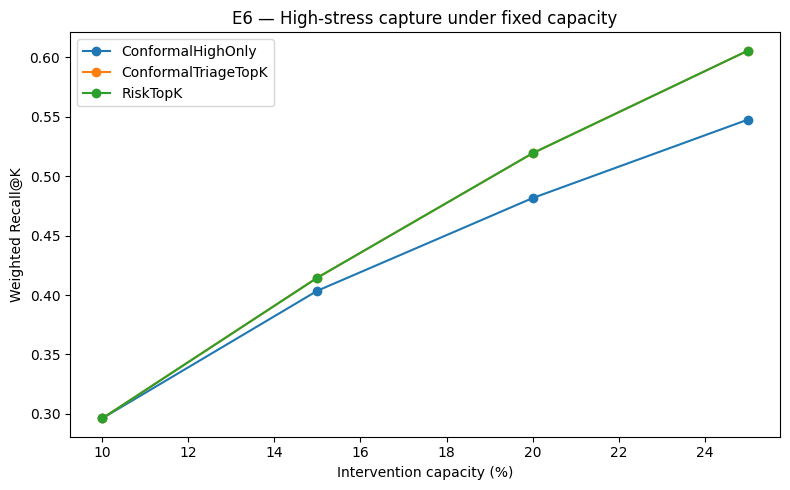

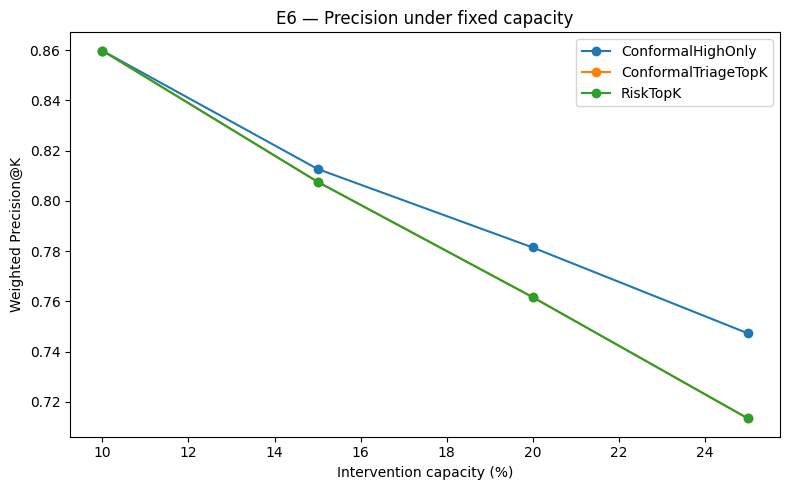

In [12]:

# Recall@K
fig, ax = plt.subplots(figsize=(8, 5))
for policy, part in aggregate.groupby("policy"):
    ax.plot(
        part["capacity"] * 100,
        part["weighted_recall_at_k"],
        marker="o",
        label=policy,
    )
ax.set_xlabel("Intervention capacity (%)")
ax.set_ylabel("Weighted Recall@K")
ax.set_title("E6 — High-stress capture under fixed capacity")
ax.legend()
plt.tight_layout()
plt.savefig(
    RESULT_DIR / "fig_e6_recall_at_k.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

# Precision@K
fig, ax = plt.subplots(figsize=(8, 5))
for policy, part in aggregate.groupby("policy"):
    ax.plot(
        part["capacity"] * 100,
        part["weighted_precision_at_k"],
        marker="o",
        label=policy,
    )
ax.set_xlabel("Intervention capacity (%)")
ax.set_ylabel("Weighted Precision@K")
ax.set_title("E6 — Precision under fixed capacity")
ax.legend()
plt.tight_layout()
plt.savefig(
    RESULT_DIR / "fig_e6_precision_at_k.png",
    dpi=200, bbox_inches="tight"
)
plt.show()


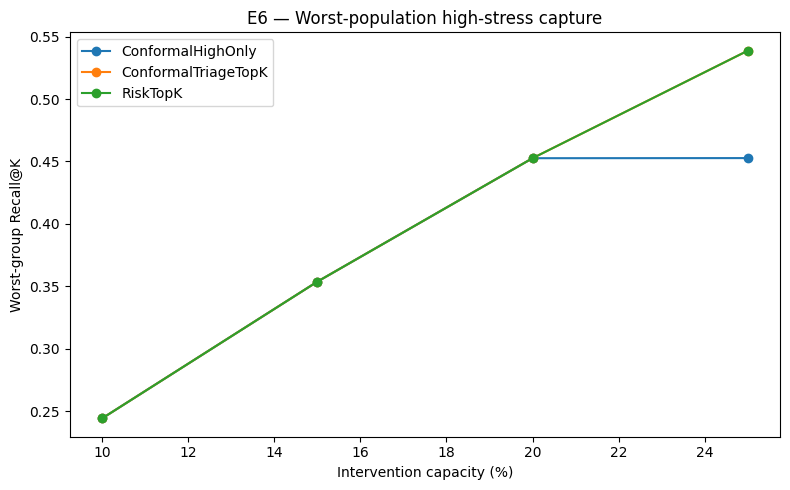

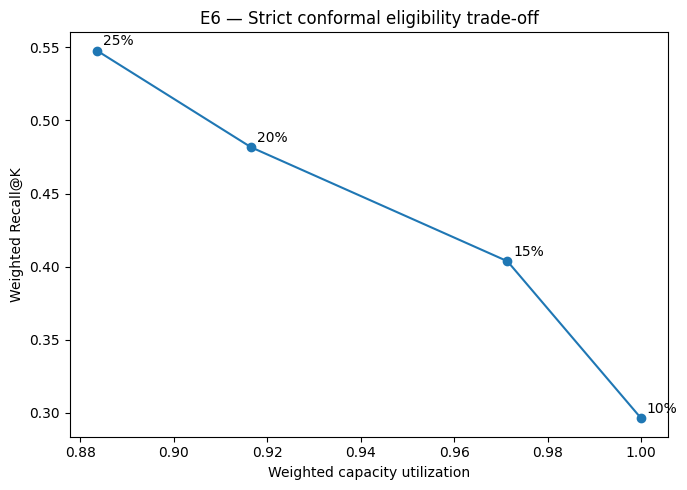

In [13]:

# Worst-group recall
fig, ax = plt.subplots(figsize=(8, 5))
for policy, part in aggregate.groupby("policy"):
    ax.plot(
        part["capacity"] * 100,
        part["worst_group_recall_at_k"],
        marker="o",
        label=policy,
    )
ax.set_xlabel("Intervention capacity (%)")
ax.set_ylabel("Worst-group Recall@K")
ax.set_title("E6 — Worst-population high-stress capture")
ax.legend()
plt.tight_layout()
plt.savefig(
    RESULT_DIR / "fig_e6_worst_group_recall_at_k.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

# Recall vs capacity utilization for strict conformal high-only
strict = aggregate[
    aggregate["policy"] == "ConformalHighOnly"
]
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(
    strict["weighted_capacity_utilization"],
    strict["weighted_recall_at_k"],
    marker="o",
)
for _, row in strict.iterrows():
    ax.annotate(
        f"{int(row['capacity']*100)}%",
        (
            row["weighted_capacity_utilization"],
            row["weighted_recall_at_k"],
        ),
        xytext=(4, 4),
        textcoords="offset points",
    )
ax.set_xlabel("Weighted capacity utilization")
ax.set_ylabel("Weighted Recall@K")
ax.set_title("E6 — Strict conformal eligibility trade-off")
plt.tight_layout()
plt.savefig(
    RESULT_DIR / "fig_e6_conformal_capacity_utilization.png",
    dpi=200, bbox_inches="tight"
)
plt.show()



# Interpretation logic

## If RiskTopK dominates

Then the probability ranking is already the most efficient use of scarce intervention slots.  
Conformal uncertainty remains useful for **confidence communication and review routing**, but not necessarily for maximizing captured high-stress cases at fixed \(K\).

## If ConformalHighOnly improves precision but leaves capacity unused

Then singleton-high predictions are a **high-confidence intervention subset**, but are insufficient as the sole institutional triage mechanism.

## If ConformalTriageTopK improves worst-group Recall@K

Then uncertainty-aware prioritization adds operational value beyond pure risk ranking.

## If SourceRecall80 requires >25% intervention

Then a sensitivity target learned from source populations is institutionally infeasible under the tested resource constraints.

## Important claim boundary

E6 evaluates **screening prioritization efficiency**, not clinical benefit.  
`High-stress captured` means correctly prioritized benchmark cases, not successful treatment outcomes.


In [14]:

manifest = {
    "experiment": "E6 Capacity-Constrained Intervention Policy",
    "dataset_rows_known_group": int(len(e6_df)),
    "excluded_missing_group": int(df[GROUP].isna().sum()),
    "base_model": "group-blind Logistic Regression",
    "features": FEATURES,
    "groups": groups,
    "n_repeats": N_REPEATS,
    "source_calibration_fraction": SOURCE_CAL_FRAC,
    "target_recall_constraint": TARGET_RECALL,
    "mondrian_alpha": ALPHA,
    "capacities": CAPACITIES,
    "capacity_policies": [
        "RiskTopK",
        "ConformalHighOnly",
        "ConformalTriageTopK",
    ],
    "noncapacity_benchmarks": [
        "SourceRecall80",
        "MondrianSingletonHigh90",
    ],
    "seed": SEED,
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "sklearn": sklearn.__version__,
}

with open(
    RESULT_DIR / "run_manifest.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(manifest, f, indent=2)

print("Saved outputs:")
for p in sorted(RESULT_DIR.glob("*")):
    print("-", p)


Saved outputs:
- student_stress_e6_outputs/e6_capacity_results_by_repeat.csv
- student_stress_e6_outputs/e6_capacity_summary_by_group.csv
- student_stress_e6_outputs/e6_capacity_weighted_worst_summary.csv
- student_stress_e6_outputs/e6_noncapacity_benchmark_summary.csv
- student_stress_e6_outputs/e6_noncapacity_benchmarks_by_repeat.csv
- student_stress_e6_outputs/e6_policy_attribution_vs_risk.csv
- student_stress_e6_outputs/e6_recall80_capacity_feasibility.csv
- student_stress_e6_outputs/e6_source_policy_thresholds.csv
- student_stress_e6_outputs/e6_target_row_predictions.csv
- student_stress_e6_outputs/fig_e6_conformal_capacity_utilization.png
- student_stress_e6_outputs/fig_e6_precision_at_k.png
- student_stress_e6_outputs/fig_e6_recall_at_k.png
- student_stress_e6_outputs/fig_e6_worst_group_recall_at_k.png
- student_stress_e6_outputs/run_manifest.json
